# Liquid xenon time projection chambers (TPC):

Most of you are familiar with how our TPC works, which is in short: An interaction inside the sensitive volume of our detector will create photons and charge carriers. The photons are directly detected by our PMT arrays and form the prompt first scintillation signal called S1. At the same time the electrons are drifted in an electric field to the liquid-gas interface where a second, stronger field extracts the electrons into the gas-phase. Here, the electrons are accelerated until they can excite further xenon atoms to produce a second scintillation signal which is proportional to the number of extracted electrons. Based on the PMT pattern of the S2 light we can infer the x-y-position of the signal, from the electron drift we can infer z, and thus get a full 3d vertex reconstruction. This is also depicted in the subsequent figure.

<center><img src="images/tpc_nt.png" width="800"/></center>

While this is the rough procedure and sort of common knowledge, we tend to forget about the details which are required to identify the S1 and S2 signals based on the recorded PMT pulses. In addition, we must correct our signals for various detector specific effects in order to make sense out of our data. In the following we will walk through the different levels of our data reconstruction for a better technical understanding.

# Data structure and detector physics

In our first tutorial we have seen how data can be loaded, and that data is in general organized as time intervals in strax. In this tutorial we want to focus now on the different levels of so-called **data-types** which abstrax provides to refine our data from digitized raw PMT pulses, to S1 and S2 pairs which we call **events**. The transformation of information in a strax-based framework is achieved via so called **plugins**. They can be depicted as exchangeable building blocks which tell strax based on the lineage how a certain data-type is to be transformed to the next higher level data-type. 

The entire data structure in abstrax can be divided into 3 to 5 different levels as illustrated in the subsequent figure (this figure is only for illustration. The plugin structure in abstrax is slightly different and is shown in the README of the repository):

<center><img src="images/DataTypes.png" width="800"/></center>

For data taking the lowest level is provided by the `DAQReader` plugin. This plugin has some special requirements as it represents the starting point into the strax-framework. This starting plugin does not necessarily have to read binary files from a data acquisition system. In `ember`, the waveform simulation package associated with `abstrax`, the lowest entry point is given by a plugin that reads simple csv files. The `DAQReader` of abstrax is also only a dummy which reads already existing processed binary files. Tutorial 5 shows a small example of how a `DAQReader` plugin for binary files of a triggered DAQ could look like.
Most generally the data provided by the `DAQReader` are the raw, digitized PMT signals. Thus, their respective data size is quite large, in the order of hundreds of GB per run for an LZ or XENONnT-sized detector. However, the raw data is also not needed for most of the different analyses except for the PMT calibrations like PMT gain, SPE acceptance or PMT afterpulses. Associated with the raw data and the `DAQReader` is the `PulseProcessing` plugin that searches for single PMT signals and applies zero length encoding to the recorded waveforms. Depending on your application this might be already the case and this plugin is not required anymore. 

The next higher level of information are `Peaklets` which is a pre-stage of S1 and S2 peaks. In XENONnT it turned out to be advantageous to build first short peaks (therefore peaklets) to better discriminate S1s from S2 signals. Based on these peaklets `Peaks` are built by merging S2 peaklets into S2 peaks, called `merged_s2s`. S1 peaks are the same as S1 peaklets. At this data level our data is already quite a bit refined and the size is in the order of a few GB per run. Since **peaks** are trivial to compute from **peaklets**, peaks are usually not stored on disk, but **peaklets** and **merged_s2s** are. So **peaks** are trivial to load. The peak-level data is especially required when working on different detector related effects and corrections, for example the S2 x-y dependent area correction.

The highest data level are `Events` which represent pairs of S1 and S2 peaks which may represent an interaction in our detector. Unfortunately, our detectors produce many S1 and S2 signals such that a signal pairing is not always trivial. Tutorial 4 shows how data quality cuts can be applied in the strax-framework to ensure the selection of well reconstructed S1 and S2 pairs.

In this tutorial we will use three different runs for illustration:
  1. run 012882 contains a few seconds of XENONnT's data taken during the beginning of the commissioning phase of the experiment. 
  2. run 000001 and 000002 are two runs simulated with ember. The simulation uses a mock-up LZ/XENONnT-sized detector. Run 000001 is a "longer" run containing 10000, 10 keV mono-energetic beta decays. Run 000002 is a "short" run with only 100 beta events uniformly distributed between 1 keV and 10 keV. Both data sets are uniformly distributed in space. Each event is well separated, such that no event overlaps with another one.

  The simulated runs use dummy maps and do not reflect the configuration of any real detector. The lineage hashes of the data were manually altered so that the data can be loaded in abstrax without requiring the lineage of the ember simulation plugins. The lineage in the metadata file is unchanged to allow reproducibility. 

In [69]:
# First setup context again:
import strax
import abstrax

# Some other packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path


TEST_DATA = Path('../test_data').resolve()
OUTPUT_FOLDER = Path('./strax_data').resolve()

SHORT_RUN = '012882'
LONG_EMBER_RUN = '000001'
SHORT_EMBER_RUN = '000002'

st = abstrax.contexts.abstrax_context(output_folder=OUTPUT_FOLDER)
st.storage.append(strax.DataDirectory(str(TEST_DATA), readonly=True))

## Data-kind and data-type:

Nearly all of these different data levels consist of multiple plugins which provide **data-types** of the same **data-kind**. This is exemplary shown for peaks in the upper figure. Each of the indicated plugins (Peaks, PeakPositions, or PeakBasics) provide different **data-types of the same data-kind**. This means that each plugin provides information which belongs to the same time interval (which in this case represent individual peaks). In such a case we can load multiple different data-types of the same kind into the same array by doing...

In [70]:
peaks_array = st.get_array(SHORT_EMBER_RUN, ('peaks', 'peak_basics', 'peak_positions'))
peaks_array.dtype.names

('time',
 'endtime',
 'center_time',
 'area',
 'n_hits',
 'n_channels',
 'top_n_channels',
 'max_pmt',
 'max_pmt_area',
 'n_saturated_channels',
 'range_50p_area',
 'range_90p_area',
 'area_fraction_top',
 'length',
 'dt',
 'median_time',
 'rise_time',
 'tight_coincidence',
 'type',
 'max_diff',
 'min_diff',
 'first_channel',
 'last_channel',
 'x',
 'y',
 'channel',
 'area_per_channel',
 'data_top',
 'data_start',
 'data',
 'width',
 'area_decile_from_midpoint',
 'saturated_channel',
 'max_gap',
 'max_goodness_of_split')

... which provides us with additional information than just using a single data-type:

In [71]:
peaks_array = st.get_array(SHORT_EMBER_RUN, 'peak_basics')
peaks_array.dtype.names

Loading peak_basics: |          | 0.00 % [00:00<?]

('time',
 'endtime',
 'center_time',
 'area',
 'n_hits',
 'n_channels',
 'top_n_channels',
 'max_pmt',
 'max_pmt_area',
 'n_saturated_channels',
 'range_50p_area',
 'range_90p_area',
 'area_fraction_top',
 'length',
 'dt',
 'median_time',
 'rise_time',
 'tight_coincidence',
 'type',
 'max_diff',
 'min_diff',
 'first_channel',
 'last_channel')

During loading strax will automatically merge these different data-types and drop redundant fields which would appear otherwise multiple times, e.g., `time` or `endtime`.

To get an overview of all data-types abstrax provides and their data-kind, we can ask the context for the plugin which provides a data-type. Each plugin also tells us on which data-types it depends:

In [72]:
data_types = [
    'raw_records', 'records', 'pulse_counts',
    'peaklets', 'peaklet_classification', 'lone_hits', 'merged_s2s',
    'peaks', 'peak_basics', 'peak_positions',
    'events', 'event_basics', 'corrected_areas', 'energy_estimates', 'event_info',
]

for data_type in data_types:
    plugin = st.get_single_plugin(SHORT_EMBER_RUN, data_type)
    data_kind = plugin.data_kind_for(data_type)
    print(f'{data_type:<25} kind: {data_kind:<12} depends on: {plugin.depends_on}')

raw_records               kind: raw_records  depends on: ()
records                   kind: records      depends on: ('raw_records',)
pulse_counts              kind: pulse_counts depends on: ('raw_records',)
peaklets                  kind: peaklets     depends on: ('records',)
peaklet_classification    kind: peaklets     depends on: ('peaklets',)
lone_hits                 kind: lone_hits    depends on: ('records',)
merged_s2s                kind: merged_s2s   depends on: ('peaklets', 'peaklet_classification', 'lone_hits')
peaks                     kind: peaks        depends on: ('peaklets', 'peaklet_classification', 'merged_s2s')
peak_basics               kind: peaks        depends on: ('peaks',)
peak_positions            kind: peaks        depends on: ('peaks',)
events                    kind: events       depends on: ('peak_basics',)
event_basics              kind: events       depends on: ('events', 'peak_basics', 'peak_positions')
corrected_areas           kind: events       depend

A few things are worth noticing:

* Some plugins provide more than one data-type. For example `Peaklets` provides `peaklets` and `lone_hits`, which are even of different kinds, and `PulseProcessing` provides `records` and `pulse_counts`.
* `peaklet_classification` is of kind `peaklets`, so it can be loaded together with `peaklets`. We will make use of this later.
* `event_info` does not compute anything new, it only merges `event_basics`, `corrected_areas` and `energy_estimates` into one data-type for convenience.
* Not every data-type is stored on disk. Whether a plugin saves its output is defined by its `save_when` attribute. We will see this later for `peaks`.

# Pulses

The lowest data level is given by pulses provided by the `DAQReader` and `PulseProcessing`. A pulse represents the charge signal recorded by a single PMT over a given time. The data-types (and kinds) provided by the two plugins are called `raw_records` and `records` respectively. A single PMT **pulse** can be fragmented over multiple `raw_records` or `records`. This is due to the fact, that numpy arrays, which we use to handle and store our data, can only store information in "rectangular" shaped buffers. 

To illustrate what this means let us load some data first:

In [73]:
raw_records = st.get_array(SHORT_RUN, 'raw_records', seconds_range=(0, 10))
st.make(SHORT_RUN, 'records') # We need to make records first to make the time selection available:
records = st.get_array(SHORT_RUN, 'records', seconds_range=(0, 10))

Loading raw_records: |          | 0.00 % [00:00<?]

Loading records: |          | 0.00 % [00:00<?]

In [74]:
raw_records.dtype.names

('time',
 'length',
 'dt',
 'channel',
 'pulse_length',
 'record_i',
 'baseline',
 'data')

Each (raw) record has a field `data` which contains the waveform fragment of a pulse. This data buffer has a length of 110 samples, and each sample represents the signal charge recorded within a 10 ns interval. Thus, a single fragment can store a pulse which has a total length of 1.1 µs.

In [75]:
len(raw_records['data'][0])

110

Like all strax data, each fragment is a time interval: `time` is the start time in ns since the unix epoch, `dt` the width of a sample in ns and `length` the number of samples which contain data. The end time is not stored for raw records, but can be computed with `strax.endtime` which returns `time + length * dt`:

In [76]:
raw_records['time'][:3], raw_records['length'][:3], raw_records['dt'][:3], strax.endtime(raw_records[:3])

(array([124999590, 124999590, 124999600]),
 array([101, 105, 101], dtype=int32),
 array([10, 10, 10], dtype=int16),
 array([125000600, 125000640, 125000610]))

However, our PMTs might produce signals which last longer than that and thus in those cases we need to split our pulse over multiple fragments. Let us try to find such an example and plot the respective pulse. For this we have to check first the total pulse length and select the first fragment of the pulse:

In [77]:
_is_long_pulse = raw_records['pulse_length'] >= 200
i_example = 0
first_fragment_long_pulse = raw_records[_is_long_pulse][i_example]

To check which fragment of a pulse we selected one can use the `record_i` field which represents the index of the ith fragment within a pulse.

In [78]:
np.unique(raw_records[_is_long_pulse]['record_i'], return_counts=True)

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
        17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27], dtype=int16),
 array([2610, 2610, 2212, 1077,  633,  419,  284,  197,  138,  107,   96,
          83,   68,   54,   43,   30,   27,   21,   18,   13,   10,    8,
           8,    4,    1,    1,    1,    1]))

For our selected first fragment of a long pulse the index should be zero:

In [79]:
first_fragment_long_pulse['record_i']

np.int16(0)

In order to select the second fragment we need to take into account that in strax data is first sorted by time and then by PMT channel (in case multiple PMTs detected some light within 10 ns). This means that if we select the second fragment through its start time...

In [80]:
_has_start_time_of_second_fragment = raw_records['time'] == (first_fragment_long_pulse['time'] + 1100)
raw_records[_has_start_time_of_second_fragment]

array([(125492870, 91, 10, 231, 201, 1, 0, [15981, 15951, 15963, 15985, 15991, 15991, 15993, 15992, 15998, 15998, 15996, 15997, 15999, 16002, 15995, 15987, 15959, 15982, 15991, 15997, 15998, 15996, 15998, 15997, 15997, 15998, 15997, 15999, 15998, 16000, 15999, 15999, 15999, 16000, 15998, 15998, 15998, 16001, 16002, 16003, 15985, 15972, 15990, 15996, 15997, 16001, 15998, 15995, 15996, 15999, 15997, 15999, 15999, 16002, 15999, 16000, 15998, 16000, 16001, 16002, 15998, 16002, 16001, 16003, 16001, 16005, 16001, 15999, 15999, 16002, 16000, 15998, 16004, 16001, 15999, 16001, 15998, 16003, 16001, 16002, 15999, 15999, 15999, 16002, 15999, 16001, 16001, 15998, 15999, 16000, 15998,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0,     0])],
      dtype=[(('Start time since unix epoch [ns]', 'time'), '<i8'), (('Length of the interval in samples', 'length'), '<i4'), (('Width of one sample [ns]', 'dt'), '<i2'), (('Channel/P

... we might find back multiple fragments as there are multiple channels, and we need therefore to select also the correct channel:

In [81]:
_is_second_fragment = _has_start_time_of_second_fragment & (raw_records['channel'] == first_fragment_long_pulse['channel'])
second_fragment_of_long_pulse = raw_records[_is_second_fragment][0]

And now we can plot the complete pulse:

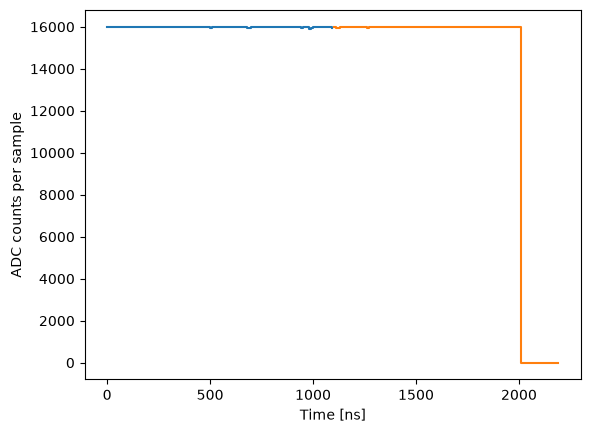

In [82]:
plt.step(np.arange(110)*10, first_fragment_long_pulse['data'], where='post')
plt.step(np.arange(110)*10+1100, second_fragment_of_long_pulse['data'], where='post')
plt.xlabel('Time [ns]')
plt.ylabel('ADC counts per sample')
plt.show()

In this form the plot is not much of use for us, and the reason is another feature one needs to keep in mind when working with pulses. In order to reduce the amount of data used per pulse we apply a zero length encoding (ZLE) which means that samples which do not contain any data are set to zero within the 110 sample buffer. This is also true for signals which are shorter than 110 samples. In both cases we must truncate the waveform according to the `length` field of the fragment:

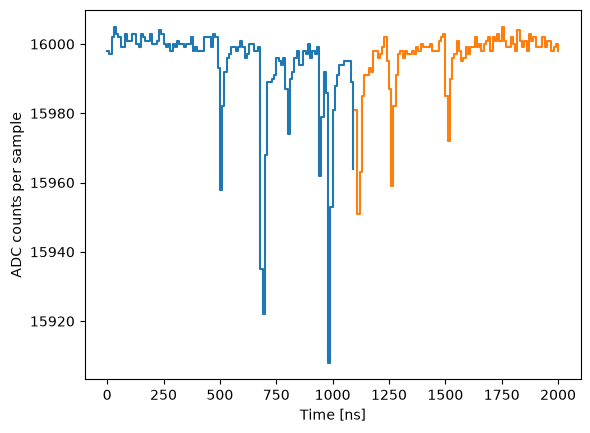

In [83]:
plt.step(np.arange(110)*10, first_fragment_long_pulse['data'], where='post')
plt.step(np.arange(second_fragment_of_long_pulse['length'])*10+1100, second_fragment_of_long_pulse['data'][:second_fragment_of_long_pulse['length']], where='post')
plt.xlabel('Time [ns]')
plt.ylabel('ADC counts per sample')
plt.show()

We can also have a look at the corresponding record. We can reuse the selection masks we made for `raw_records`, since `PulseProcessing` keeps exactly one record per raw record and does not change their order (it would only drop records of channels which do not belong to the TPC):

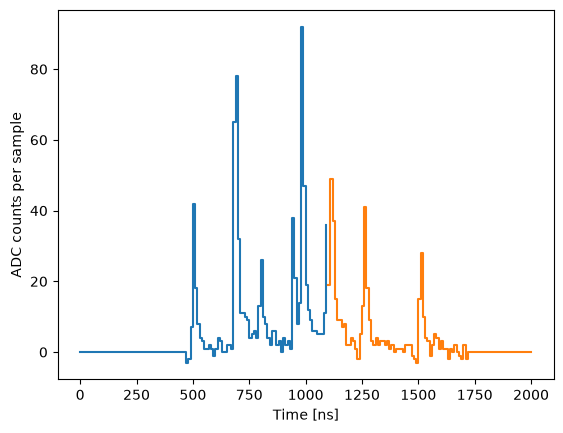

In [84]:
first_fragment_long_pulse = records[_is_long_pulse][i_example]
second_fragment_of_long_pulse = records[_is_second_fragment][0]

plt.step(np.arange(110)*10, first_fragment_long_pulse['data'], where='post')
plt.step(np.arange(second_fragment_of_long_pulse['length'])*10+1100, second_fragment_of_long_pulse['data'][:second_fragment_of_long_pulse['length']], where='post')
plt.xlabel('Time [ns]')
plt.ylabel('ADC counts per sample')
plt.show()

In `records` each pulse is baseline subtracted and flipped. In addition, a hitfinder algorithm searches for **hits**, a consecutive number of samples above threshold, and applies also zero length encoding to all samples which are not found within a hit(let) (we will explain the difference between hits and hitlets in a moment). The baseline is computed from the first samples of each pulse, which is why the waveform is zero at the start of the pulse. It should also be noticed that only the integer part of the baseline is subtracted as the waveform is stored as a 16 bit integer. This must be kept in mind if one wants to compute the total charge of a signal.

`strax` also provides some functions of general use that can be used to identify consecutive pulse fragments faster:

In [85]:
previous_record_index, next_record_index = strax.record_links(records)
previous_record_index, next_record_index

(array([   -1,    -1,    -1, ..., 34427, 34431, 34432], shape=(34445,)),
 array([-1, -1, -1, ..., -1, -1, -1], shape=(34445,)))

... to find the index of the next and previous fragment belonging to the same pulse...

In [86]:
previous_record_index[_is_long_pulse][i_example], next_record_index[_is_long_pulse][i_example]

(np.int64(-1), np.int64(73))

... which returns -1 in case there is not any additional fragment. Plotting again the waveform: 

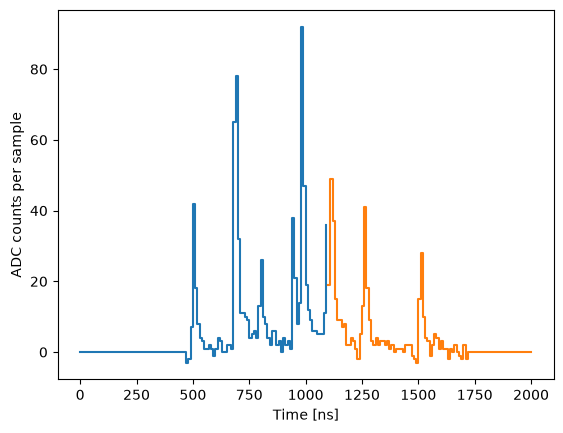

In [87]:
second_fragment_of_long_pulse = records[next_record_index[_is_long_pulse][i_example]]

plt.step(np.arange(110)*10, first_fragment_long_pulse['data'], where='post')
plt.step(np.arange(second_fragment_of_long_pulse['length'])*10+1100, second_fragment_of_long_pulse['data'][:second_fragment_of_long_pulse['length']], where='post')
plt.xlabel('Time [ns]')
plt.ylabel('ADC counts per sample')
plt.show()

The baseline for each pulse (so all fragments of a pulse) is computed over the first $n$ samples of the first fragment of a waveform. To check the exact number we can again have a look at the config...

In [88]:
st.show_config('records', pattern='baseline_samples')

,option,default,current,applies_to,help
0,baseline_samples,40,<OMITTED>,"(records, pulse_counts)",Number of samples at the start of each pulse u...


... which shows us that by default the first 40 samples are used. As mentioned before a hit is given by the consecutive number of samples which are exceeding a user specified threshold. Each of these hits is then subsequently extended by a fixed number of samples to include also the rising and falling edges of the PMT signal. To see which settings are affecting our hits we can use again `show_config` with wild cards:

In [89]:
st.show_config('records', pattern='*hit*')

,option,default,current,applies_to,help
0,hit_min_amplitude,15,<OMITTED>,"(records, pulse_counts)",Minimum hit amplitude in ADC counts above base...
1,save_outside_hits,"(3, 20)",<OMITTED>,"(records, pulse_counts)","(left, right) samples to preserve on each side..."


We can run the hitfinder on our records ourselves using the same threshold of 15 ADC counts. Each hit stores in `record_i` the index of the record in which it was found, and in `left` and `right` the first and the last (exclusive) sample of the hit within this record:

In [90]:
hits = strax.find_hits(records, min_amplitude=15)

index_of_first_fragment = np.where(_is_long_pulse)[0][i_example]
hits_in_first_fragment = hits[hits['record_i'] == index_of_first_fragment]
hits_in_first_fragment[['left', 'right', 'height', 'area']]

array([( 50,  52, 42.700195,  61.40039 ),
       ( 68,  71, 78.700195, 177.10059 ),
       ( 80,  81, 26.700195,  26.700195),
       ( 94,  96, 38.700195,  60.40039 ),
       ( 98, 101, 92.700195, 160.10059 ),
       (109, 110, 36.700195,  36.700195)],
      dtype={'names': ['left', 'right', 'height', 'area'], 'formats': ['<i2', '<i2', '<f4', '<f4'], 'offsets': [20, 22, 36, 16], 'titles': ['Index of sample in record in which hit starts', 'Index of first sample in record just beyond hit (exclusive bound)', 'Maximum amplitude above baseline [ADC counts]', 'Integral [ADC x samples]'], 'itemsize': 48})

Let us plot these hits (orange bands) on top of the first fragment of our long pulse:

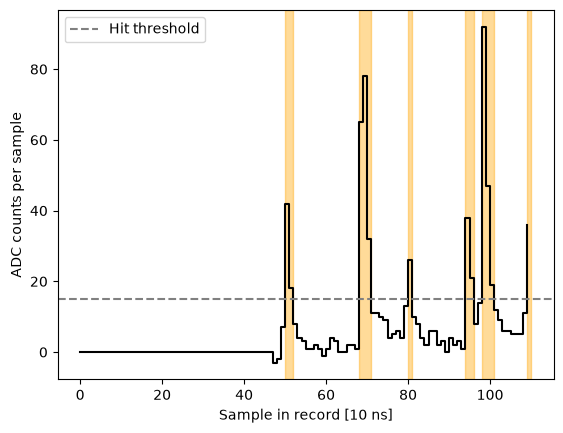

In [91]:
first_fragment = records[index_of_first_fragment]
plt.step(np.arange(first_fragment['length']), first_fragment['data'][:first_fragment['length']], where='post', color='k')
for hit in hits_in_first_fragment:
    plt.axvspan(hit['left'], hit['right'], color='orange', alpha=0.4)
plt.axhline(15, color='gray', ls='dashed', label='Hit threshold')
plt.xlabel('Sample in record [10 ns]')
plt.ylabel('ADC counts per sample')
plt.legend()
plt.show()

The samples around the hits which are not set to zero are the 3 samples to the left and 20 samples to the right which `PulseProcessing` keeps (`save_outside_hits`). A hit together with such an extension to the left and right is what we call a **hitlet**. Hitlets are used for example when integrating the charge of lone hit, or building the summed waveform of a peak.

# Peaklets, MergedS2s and Peaks

The lowest level data-type which is normally used in an analysis is the `peaklets` data-type. The grouping of hits into peaklets is usually a bit more complicated and involves a few steps which we will quickly walk through in the following. 

Peaklets formation starts with a second iteration of the hitfinder algorithm as we only pass the `records` from PulseProcessing to Peaklets, but not the information about hits. Hits are afterwards grouped into peaklets. The grouping works as follows...
* The grouping searches for gaps between hits. If two consecutive hits are more than 700 ns apart a new **peaklet candidate** is formed.
*  A peaklet candidate becomes a peaklet if at least two hits of two different PMT channels are found within the peaklet.
*  Each peaklet interval is extended to the left and right (LE, RE) by the same time intervals as when forming hitlets from hits (30 ns to the left and 200 ns to the right).
*   If a peaklet last longer than 10 ms it is artificially truncated and a new peaklet candidate starts.

All these numbers are the current default settings of the `Peaklets` plugin (`peaklet_gap_threshold`, `peak_min_pmts`, `peak_left_extension`, `peak_right_extension` and `peaklet_max_duration`) and can be adjusted to the needs of your detector. You can check them with `st.show_config('peaklets')`.

The procedure is also depicted in the subsequent figure. The different colors represent signals in different PMT channels. Hits which are not grouped into any peaklet are "lone-hits".

<center><img src="images/PeakletBuilding.png" width="800"/></center>

After forming the initial peaklets they are split according to their summed waveform based on a **[modified natural breaks algorithm](https://github.com/AxFoundation/strax/pull/225)** which computes a goodness of split (1 == split, 0 == no split point). Each peak is split at the largest goodness of split value exceeding an area dependent threshold. Small peaks have a smaller threshold than larger peaks. Subsequently the goodness of split for a multi-scatter S2 signal is shown. 

<center><img src="images/GoodnessOfSplitt.png" width="600"/></center>

The splitting is applied recursively to the resulting new peaks, until no further split points can be found, or a maximum number of iterations is exceeded. In the upper example the former is the case as shown here for the second of the two split peaks.

<center><img src="images/GoodnessOfSplitt_sub_peak.png" width="600"/></center>

Afterwards peaklets are classified into S1, S2 or unknown by the `PeakletClassification` plugin using their respective properties. The classification is done using some simplified metrics like the rise time of the signal and its area fraction seen by the top PMT array. The neat thing about plugins is that they can be replaced at any time as we will see in the third tutorial without changing a single line of a python module file to test new things. This enables and encourages analysts to develop new improved processing methods. For example in XENONnT the simplified classification method was replaced by a machine learning classifier using Self-Organizing Maps (SOM). Tutorial 3 will show how the current dummy S2 position reconstruction can be replaced with a different algorithm on the fly while working in an analysis notebook.

In the last step all peaklets which have been classified as an S2 are merged via the `MergedS2s` plugin into bigger S2 peaks (this is mostly required for small single electron S2s that can diffuse apart from each other in large detectors like the planned XLZD experiment). The merging is decided based on peaklet size and gap between peaklets in time.

Now let us check the procedure by ourselves. For this purpose we want to load our `records` and some peaks including the data-type `peak_basics` which is of the same kind as `peaks`. However, when working with peaks you should always be aware that certain data-types of this kind are a bit larger, and that you might want to use the data reduction techniques we learned in tutorial 1. For this part we use our short simulated run with only 100 events. `st.size_mb` only works for data which is stored, so we first process the run up to `event_basics` with `st.make` (this stores all data-types on the way which are saved by default). Afterwards we compare the sizes of the different data levels:

In [92]:
st.make(SHORT_EMBER_RUN, 'event_basics')

In [93]:
st.size_mb(SHORT_EMBER_RUN, 'raw_records'), st.size_mb(SHORT_EMBER_RUN, 'peaklets'), st.size_mb(SHORT_EMBER_RUN, 'peak_basics'), st.size_mb(SHORT_EMBER_RUN, 'event_basics')

(20.3862, 1.040175, 0.01683, 0.0432)

As you can see we are using peaklets as an approximation for the size of peaks. Additionally, you can see that peak(lets) is already much smaller than our records, however it is still huge compared to peak_basics which just contains some basic information of peaks, but not their waveform. By default peaks are not stored...

In [94]:
st.is_stored(SHORT_EMBER_RUN, 'peaks')

False

..., which is why we had to use peaklets as a proxy for the size. However, they can be easily made on the fly based on `peaklets`, `peaklet_classification` and `merged_s2s`:

In [95]:
st.is_stored(SHORT_EMBER_RUN, 'peaklets'), st.is_stored(SHORT_EMBER_RUN, 'peaklet_classification'), st.is_stored(SHORT_EMBER_RUN, 'merged_s2s')

(True, True, True)

Now let us load peaks and the records of this run:

In [96]:
peaks = st.get_array(SHORT_EMBER_RUN, ('peaks', 'peak_basics'))
records = st.get_array(SHORT_EMBER_RUN, ('records',))

Loading ('records',): |          | 0.00 % [00:00<?]

To sort our records into intervals belonging to the respective peaks we can use `strax.touching_windows`. It will return us start/end indices of things which are contained in the time window of a container.

In [97]:
strax.touching_windows?

Signature: strax.touching_windows(things, containers, window=0)
Docstring:
Return array of (start, exclusive end) indices into things which extend to within window of
the container, for each container in containers.

:param things: Sorted array of interval-like data.
    We assume all things and containers are sorted by time.
    When endtime are not sorted, it will return indices
    of the first and last things which are touching the container.
:param containers: Sorted array of interval-like data. Containers are
    allowed to overlap.
:param window: threshold distance for touching check.

For example:
    - window = 0: things must overlap one sample
    - window = -1: things can start right after container ends
        (i.e. container endtime equals the thing starttime, since strax
        endtimes are exclusive)
File:      /mnt/d/XLZD/mymodules/strax/strax/processing/general.py
Type:      function

In [98]:
tw_index = strax.touching_windows(records, peaks)

/mnt/d/XLZD/mymodules/strax/strax/processing/general.py:397: UserWarning: endtime of things is not sorted! touching_windows will return the indices of the first and last things which are touching the container.
  warnings.warn(


The warning can be ignored here (you might have already seen it when we loaded `peaks` at the beginning): records of different channels overlap in time, thus their end times are not sorted although their start times are. In this case `touching_windows` returns the index of the first and last record which touch the peak, so the range might also contain a few records in between, but they have to overlap with the peak by definition.

Now let us plot the summed waveform of a typical small S1 signal. We can select peaks with certain properties via a simple selection mask:

In [99]:
_is_small_s1 = ((peaks['type'] == 1) 
              & (peaks['area'] < 10)
              & (peaks['area_fraction_top'] > 0.6)
             )

The available fields can be checked again via

In [100]:
st.data_info('peaks')

,Field name,Data type,Comment
0,time,int64,Start time since unix epoch [ns]
1,length,int32,Length of the interval in samples
2,dt,int32,Width of one sample [ns]
3,channel,int16,Channel/PMT number
4,type,int8,Classification of the peak(let)
...,...,...,...
20,max_goodness_of_split,float32,Maximum interior goodness of split
21,max_diff,int32,Largest time difference between apexes of hits...
22,min_diff,int32,Smallest time difference between apexes of hit...
23,first_channel,int16,First channel/PMT number inside peak (sorted b...


In [101]:
st.data_info('peak_basics')

,Field name,Data type,Comment
0,time,int64,Start time since unix epoch [ns]
1,endtime,int64,Exclusive end time since unix epoch [ns]
2,center_time,int64,Weighted average center time of the peak [ns]
3,area,float32,Peak integral in PE
4,n_hits,int32,Number of hits contributing at least one sampl...
...,...,...,...
18,type,int8,Classification of the peak(let)
19,max_diff,int32,Largest time difference between apexes of hits...
20,min_diff,int32,Smallest time difference between apexes of hit...
21,first_channel,int16,First channel/PMT number inside peak (sorted b...


In [102]:
selected_s1_peaks = peaks[_is_small_s1]
tw_index_selected_peak = tw_index[_is_small_s1]

Now let us plot the summed waveform and the underlying hits:

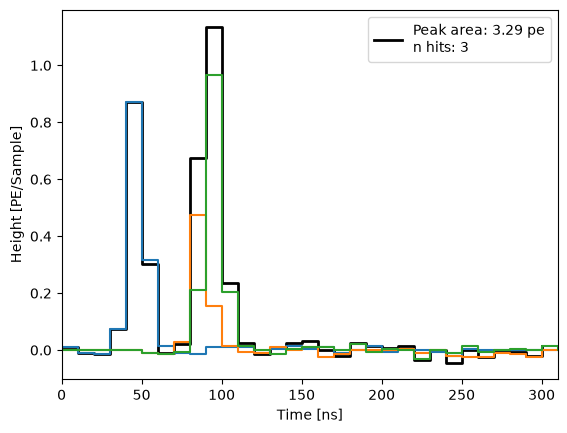

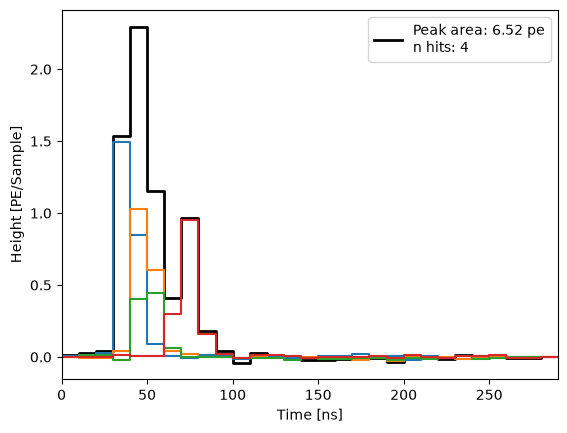

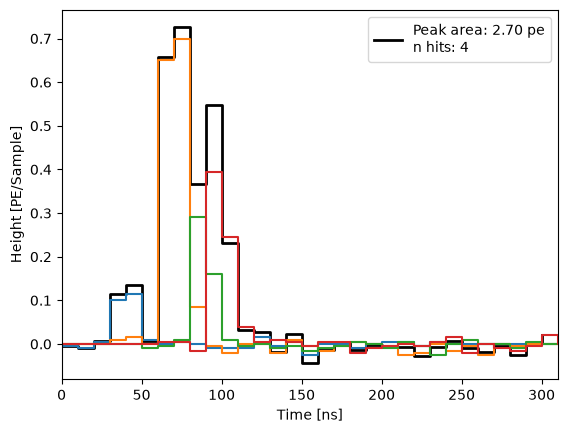

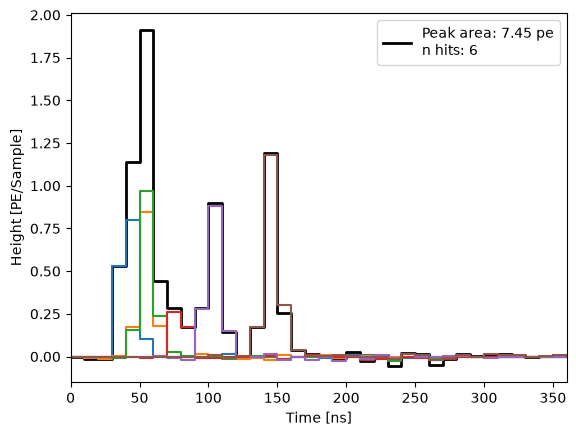

In [103]:
# Before we can make the plot we need to know the conversion factor
# to convert the measured charge into units of photon equivalents.
# We will explain more about this conversion subsequently.
plugin = st.get_single_plugin(SHORT_EMBER_RUN, 'peaklets')

for _tw, p in zip(tw_index_selected_peak[:5], selected_s1_peaks[:5]):
    figure, axis = plt.subplots()
    plt.step(np.arange(p['length']) * p['dt'], p['data'][:p['length']],
             where='post', color='k', lw=2, label=f'Peak area: {p["area"]:.2f} pe\nn hits: {p["n_hits"]}')

    # Now plot the individual records for the given peak:
    records_in_peak = records[_tw[0]:_tw[1]]
    for r in records_in_peak:
        start_time_in_peak = r['time'] - p['time']
        plt.step(np.arange(r['length']) * r['dt'] + start_time_in_peak,
                 r['data'][:r['length']] * plugin.to_pe[r['channel']],
                 where='post')
    plt.xlabel('Time [ns]')
    plt.ylabel('Height [PE/Sample]')
    plt.xlim(0, p['length'] * p['dt'])
    plt.legend()
    plt.show()

## Peak area and area fraction top:

After forming peaklets, the respective summed waveform is computed. Additionally, the summed waveform of only the top PMT array is computed. During this step the waveform is also converted from ADC counts into a charge unit in units of single photon charge equivalents (Photoelectrons, PE). The corresponding conversion factors are evaluated based on PMT calibration data. A typical charge calibration looks like shown below. 

<center><img src="images/PMT2028_v1.png" width="600"/></center>

The distribution is usually given by a pedestal peak which corresponds to the average charge if no signal is present (that is why the pedestal is symmetrically distributed around zero), which is followed by the response of single (red dashed-dotted) and two photon signals (brown). Sometimes electrons are lost during the amplification stage of a photon signal. This leads to an additional component of "underamplified" signals which are depicted in green. The sum of the green and red distribution make up the PMT response for single photons. The average of this joint distribution represents the average charge equivalent of a single photon which is used as the conversion factor.

The peak charge, or as we call it typically the peak "area", after the conversion is proportional to the deposited energy of a particle.

To query the conversions factors `to_pe` we can either use a plugin which uses this config...

In [104]:
plugin = st.get_single_plugin(SHORT_EMBER_RUN, 'peaklets')
plugin.to_pe

array([0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005,

... or we perform a "dry" evaluation of the corresponding setting via `URLConfig`...

In [105]:
config_url  = st.config['gain_model']
print(config_url)
strax.URLConfig.evaluate_dry(config_url, run_id=SHORT_EMBER_RUN)

numpy:///mnt/d/XLZD/mymodules/abstrax/abstrax/resources/fake_to_pe_494_0.005.npy


array([0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005, 0.005,
       0.005, 0.005,

Besides estimating the total charge/area of a signal, we can also estimate the fraction of area which was only seen by one of the two PMT arrays. Historically, the area fraction of the top PMT array or the asymmetry between the two arrays is used.

Plotting the area fraction top for a single run with more statistics reveals why this parameter is interesting for signal discrimination:

In [106]:
peak_basics = st.get_array(LONG_EMBER_RUN, 'peak_basics')

Loading peak_basics: |          | 0.00 % [00:00<?]

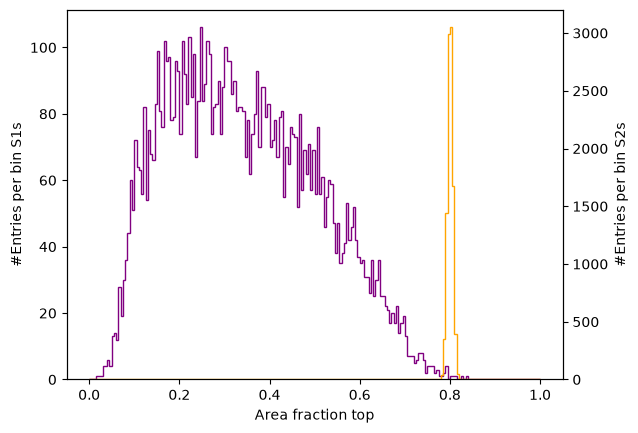

In [107]:
_is_large_s1 = ((peak_basics['type'] == 1)
                & (peak_basics['area'] >= 50)
               )

_is_large_s2 = ((peak_basics['type'] == 2)
                & (peak_basics['area'] >= 50)
               )

s1_peaks = peak_basics[_is_large_s1]
s2_peaks = peak_basics[_is_large_s2]

fig, axis = plt.subplots()
plt.hist(s1_peaks['area_fraction_top'], bins=200, range=(0, 1), histtype='step', label='S1', color='purple')
plt.xlabel('Area fraction top')
plt.ylabel('#Entries per bin S1s')
axis.twinx()
plt.hist(s2_peaks['area_fraction_top'], bins=200, range=(0, 1), histtype='step', label='S2', color='orange')
plt.ylabel('#Entries per bin S2s')
plt.show()

## Peak shape and summed waveform properties:

Peaks can be categorized and classified by a variety of different properties. Especially the shape of the peak and the area fraction of the peak are helpful for the classification. In the following we want to highlight a few of the most important parameters.

All shape parameters of a peak like its width and rise time are determined based on the deciles of integrated peak charge which we call "area". The rise-time is defined as the time between the 10 % to the 50 % area decile. The 50 % and 90 % width correspond to the inner most 50 % and 90 % area covered.

Let us check this for a few large S1 and S2 signals of our short run and start with the rise time. The positions of the area deciles are stored in the field `area_decile_from_midpoint` as the time between the decile and the 50 % area point. Index 0 corresponds to 0 % area, index 1 to 10 % area and so on:

In [108]:
peak_basics_short = st.get_array(SHORT_EMBER_RUN, ('peaks', 'peak_basics'))

_is_large_s1_short = ((peak_basics_short['type'] == 1)
                & (peak_basics_short['area'] >= 50)
               )

_is_large_s2_short = ((peak_basics_short['type'] == 2)
                & (peak_basics_short['area'] >= 50)
               )

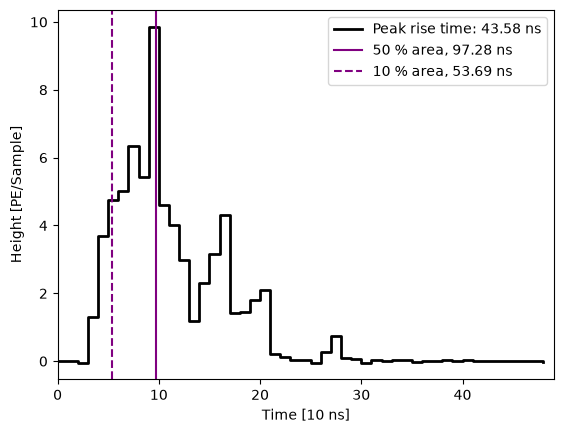

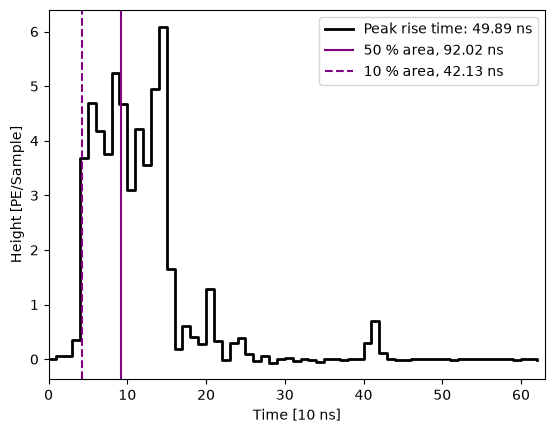

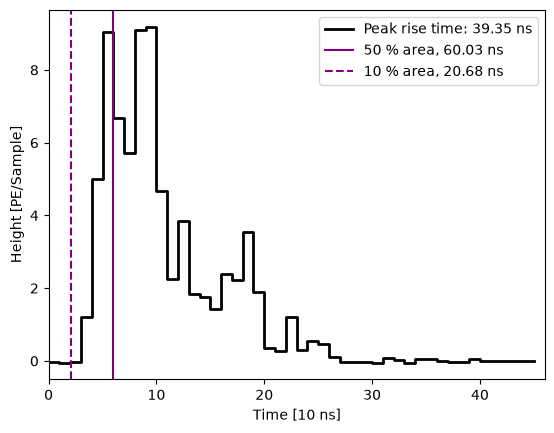

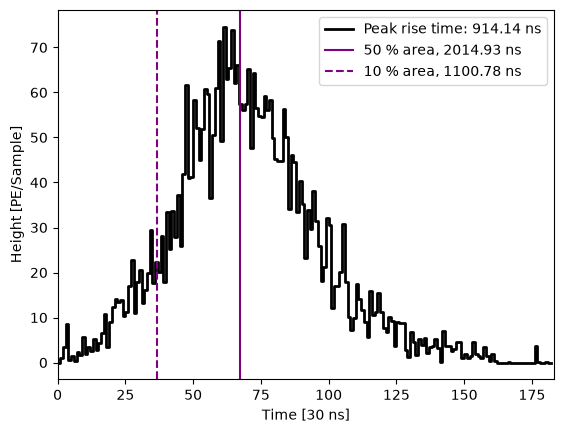

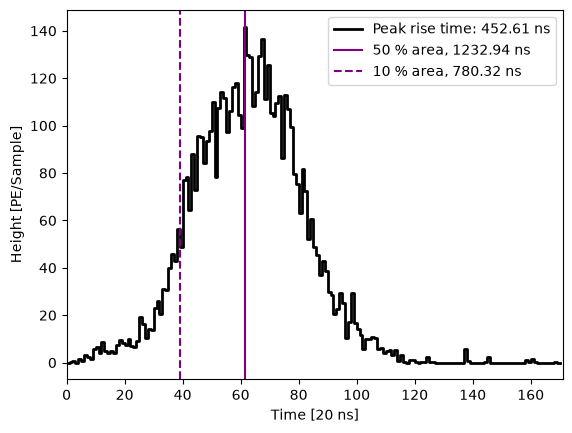

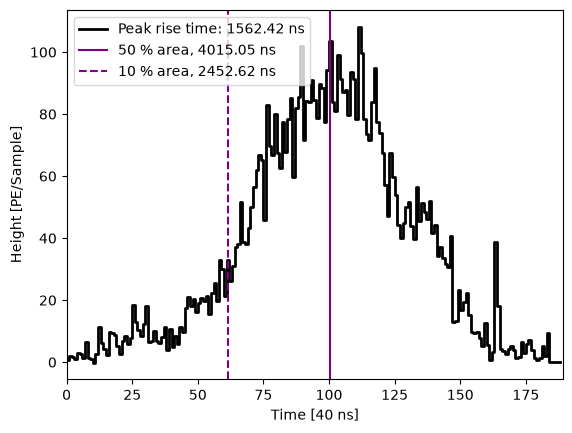

In [109]:
for p in peak_basics_short[_is_large_s1_short][:3]:
    figure, axis = plt.subplots()
    plt.step(np.arange(p['length']), p['data'][:p['length']],
             where='post', color='k', lw=2, label=f'Peak rise time: {p["rise_time"]:.2f} ns')

    area_decile_50_p_decile = (p['area_decile_from_midpoint'][5]-p['area_decile_from_midpoint'][0])/p['dt'] # in sample
    area_decile_10_p_decile = (p['area_decile_from_midpoint'][1]-p['area_decile_from_midpoint'][0])/p['dt'] # in sample
    
    plt.axvline(area_decile_50_p_decile, color='purple', label=f'50 % area, {area_decile_50_p_decile*p['dt']:.2f} ns')
    plt.axvline(area_decile_10_p_decile, color='purple', ls='dashed', label=f'10 % area, {area_decile_10_p_decile*p['dt']:.2f} ns')

    plt.xlabel(f'Time [{p["dt"]} ns]')
    plt.ylabel('Height [PE/Sample]')
    plt.xlim(0, p['length'])
    plt.legend()
    plt.show()

for p in peak_basics_short[_is_large_s2_short][:3]:
    figure, axis = plt.subplots()
    plt.step(np.arange(p['length']), p['data'][:p['length']],
             where='post', color='k', lw=2, label=f'Peak rise time: {p["rise_time"]:.2f} ns')

    area_decile_50_p_decile = (p['area_decile_from_midpoint'][5]-p['area_decile_from_midpoint'][0])/p['dt'] # in sample
    area_decile_10_p_decile = (p['area_decile_from_midpoint'][1]-p['area_decile_from_midpoint'][0])/p['dt'] # in sample
    
    plt.axvline(area_decile_50_p_decile, color='purple', label=f'50 % area, {area_decile_50_p_decile*p['dt']:.2f} ns')
    plt.axvline(area_decile_10_p_decile, color='purple', ls='dashed', label=f'10 % area, {area_decile_10_p_decile*p['dt']:.2f} ns')

    plt.xlabel(f'Time [{p["dt"]} ns]')
    plt.ylabel('Height [PE/Sample]')
    plt.xlim(0, p['length'])
    plt.legend()
    plt.show()

Now the width parameters. Note that the central 50 % and 90 % of the area are not centered around the 50 % area point (median time) for asymmetric signals like S1s. To draw the correct intervals we compute the time at which a peak reaches 5 %, 25 %, 75 % and 95 % of its area with `strax.index_of_fraction`. It returns the (fractional) sample index for each of these fractions:

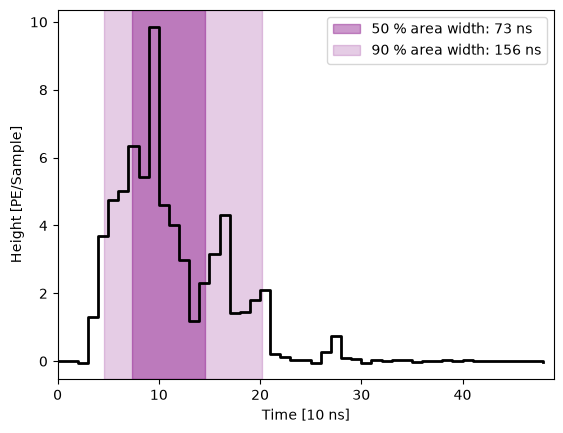

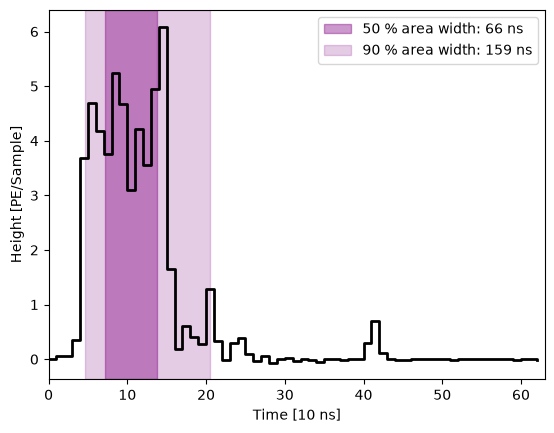

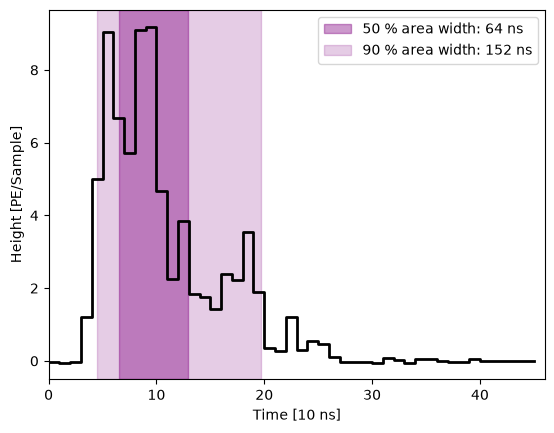

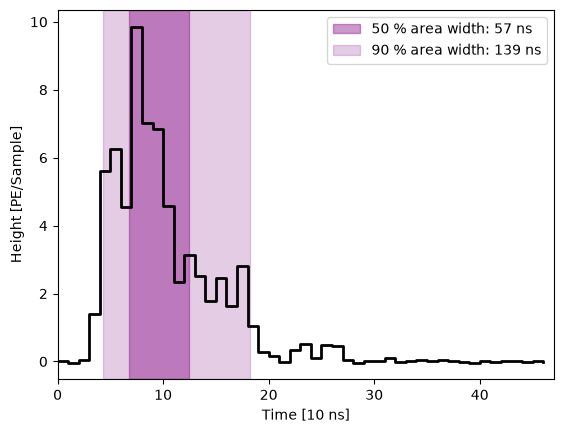

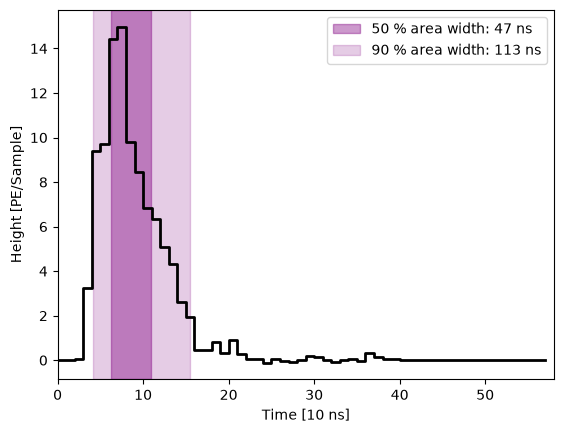

In [110]:
large_s1_peaks = peak_basics_short[_is_large_s1_short][:5]
fraction_index = strax.index_of_fraction(large_s1_peaks, np.array([0.05, 0.25, 0.75, 0.95]))

for p, index in zip(large_s1_peaks, fraction_index):
    figure, axis = plt.subplots()
    plt.step(np.arange(p['length']), p['data'][:p['length']], where='post', color='k', lw=2)

    plt.axvspan(index[1], index[2], label=f'50 % area width: {p["range_50p_area"]:.0f} ns', color='purple', alpha=0.4)
    plt.axvspan(index[0], index[3], label=f'90 % area width: {p["range_90p_area"]:.0f} ns', color='purple', alpha=0.2)

    plt.xlabel(f'Time [{p["dt"]} ns]')
    plt.ylabel('Height [PE/Sample]')
    plt.xlim(0, p['length'])
    plt.legend()
    plt.show()

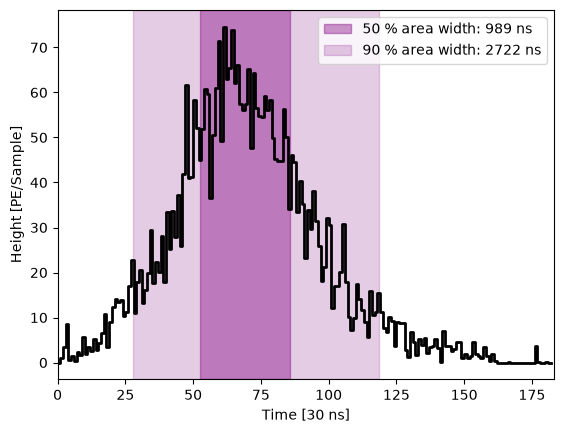

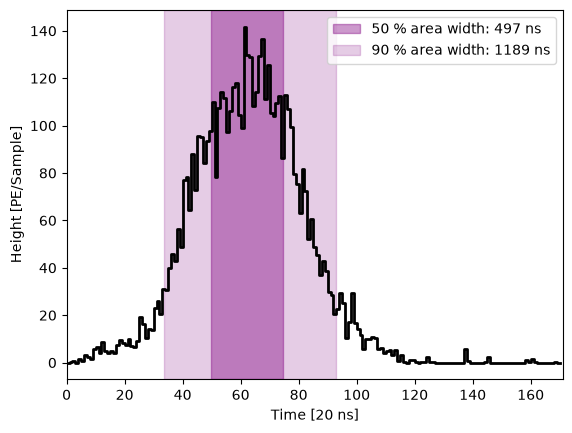

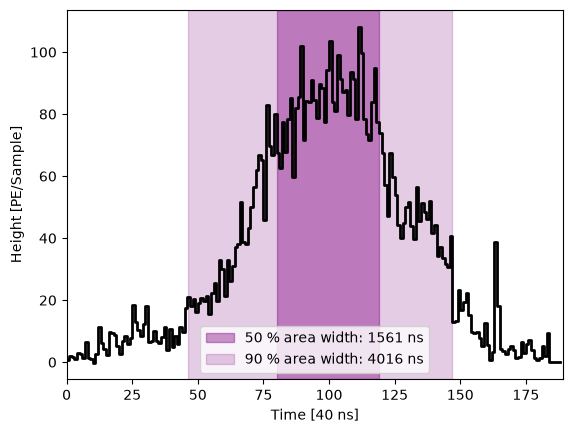

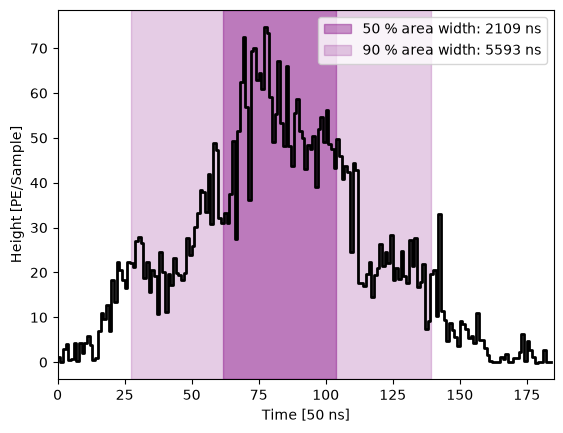

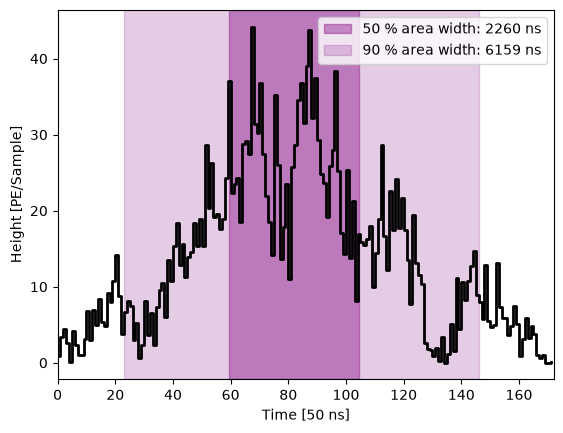

In [111]:
large_s2_peaks = peak_basics_short[_is_large_s2_short][:5]
fraction_index = strax.index_of_fraction(large_s2_peaks, np.array([0.05, 0.25, 0.75, 0.95]))

for p, index in zip(large_s2_peaks, fraction_index):
    figure, axis = plt.subplots()
    plt.step(np.arange(p['length']), p['data'][:p['length']], where='post', color='k', lw=2)

    plt.axvspan(index[1], index[2], label=f'50 % area width: {p["range_50p_area"]:.0f} ns', color='purple', alpha=0.4)
    plt.axvspan(index[0], index[3], label=f'90 % area width: {p["range_90p_area"]:.0f} ns', color='purple', alpha=0.2)

    plt.xlabel(f'Time [{p["dt"]} ns]')
    plt.ylabel('Height [PE/Sample]')
    plt.xlim(0, p['length'])
    plt.legend()
    plt.show()

By default abstrax classifies peaklets based on their area, rise time, area fraction top, the number of contributing channels and the tight coincidence (number of PMTs which see a signal within a short time window around the maximum of the peak). Based on these properties peaklets are classified as either type 0 (unknown), type 1 (S1) or type 2 (S2). The boundaries can be checked again via `st.show_config('peaklet_classification')`. In the following plot we can see the S1 and S2 populations separated by their rise time:

In [112]:
peaklets = st.get_array(LONG_EMBER_RUN, ('peaklets', 'peaklet_classification'))
rise_time = -peaklets["area_decile_from_midpoint"][:, 1] # Rise time from 10 % to 50 % area

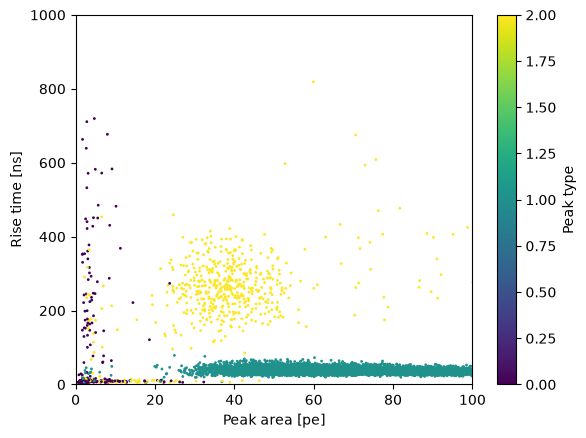

In [113]:
plt.scatter(
    peaklets['area'],
    rise_time,
    c=peaklets['type'],
    s=1,
)
plt.xlim(0, 100)
plt.ylim(0, 1000)
plt.colorbar(label='Peak type')
plt.xlabel('Peak area [pe]')
plt.ylabel('Rise time [ns]')
plt.show()

### Merged S2s:

S2 peaklets which are close in time get merged into S2s by the `MergedS2s` plugin. The maximum allowed gap between two peaklets depends on the area of the merged S2 (`s2_merge_gap_thresholds`):

In [114]:
peaklets = st.get_array(SHORT_EMBER_RUN, ('peaklets', 'peaklet_classification'))
s2_peaklets = peaklets[peaklets['type'] == 2]
merged_s2s = st.get_array(SHORT_EMBER_RUN, 'merged_s2s')

Loading merged_s2s: |          | 0.00 % [00:00<?]

In our example only 9 S2s are built from more than one S2 peaklet.

In [115]:
len(s2_peaklets), len(merged_s2s)

(110, 9)

Let us compare the waveform of merged S2s with the waveforms of their S2 peaklets. Note that the data buffer of a peak is only 200 samples long. Longer peaks are downsampled, i.e. their `dt` increases. Hence, a merged S2 and its peaklets can have different `dt` and we plot the amplitude in PE/ns. Due to the downsampling, sub-peaks may appear with a smaller amplitude in the merged S2:

In [116]:
touching_window_index = strax.touching_windows(s2_peaklets, merged_s2s)

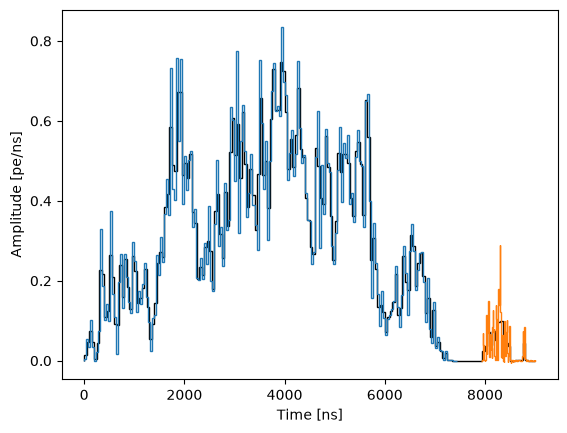

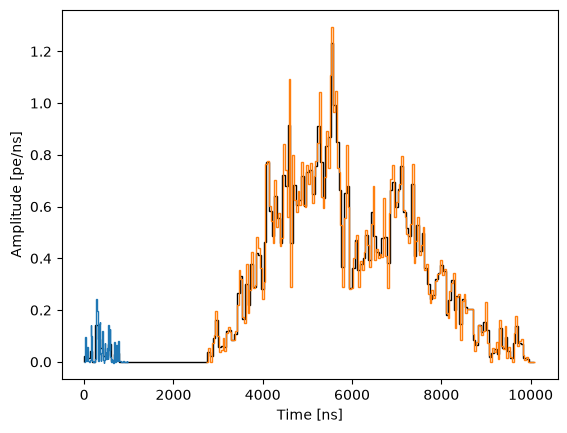

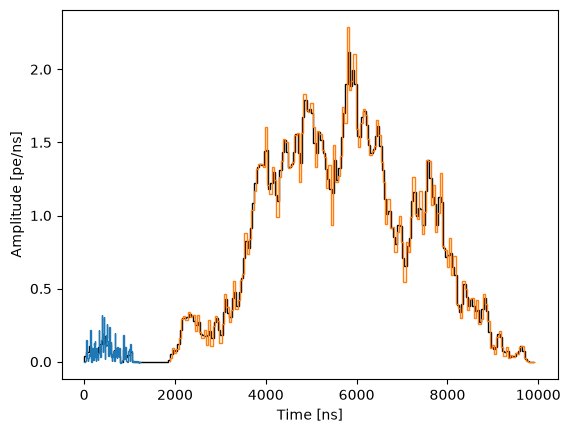

In [117]:
for tw, s2 in zip(touching_window_index[:3], merged_s2s[:3]):    
    s2_start_time = s2['time']
    peaklet_s2s = s2_peaklets[tw[0]:tw[1]]

    plt.figure()
    plt.stairs(
        s2['data'][:s2['length']]/s2['dt'],
        np.arange(s2['length']+1)*s2['dt'],
        color='k'
    )

    for peaklet in peaklet_s2s:
        peaklet_starttime = (peaklet['time'] - s2_start_time)
        plt.stairs(
            peaklet['data'][:peaklet['length']]/peaklet['dt'],
            np.arange(peaklet['length']+1)*peaklet['dt']+peaklet_starttime
        )
    plt.xlabel('Time [ns]')
    plt.ylabel('Amplitude [pe/ns]')
    plt.show()

### Lone hits:

Hits which are not grouped into any peaklet are considered as "lone-hits". These signals originate from PMT dark counts produced by the thermal emission of electrons within a PMT and stray photons bouncing around in our detectors. Each lone hit is converted into a lone hit**let** and the charge integrated. `lone_hits` is the corresponding data-type (and kind) which is also provided by `Peaklets`. 

In [118]:
lone_hits = st.get_array(LONG_EMBER_RUN, 'lone_hits')

Loading lone_hits: |          | 0.00 % [00:00<?]

Lone hits just provides a small number of different parameters...

In [119]:
lone_hits.dtype.names

('time',
 'length',
 'dt',
 'channel',
 'area',
 'left',
 'right',
 'left_integration',
 'right_integration',
 'record_i',
 'threshold',
 'height',
 'max_time')

The simulation does not contain any PMT dark counts, so the lone hits in our simulated data are PMT afterpulses. Note that the area of lone hits is not converted into PE, but is given in ADC counts × samples:

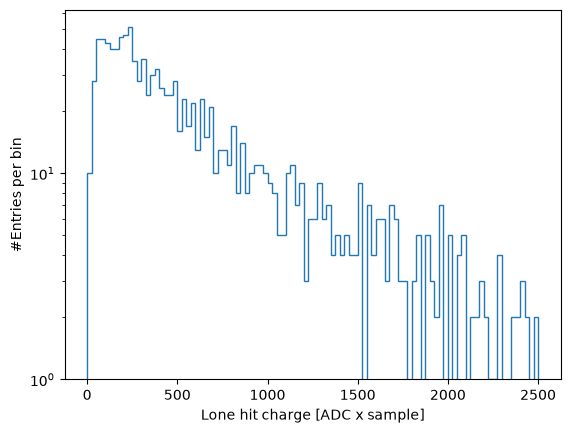

In [120]:
plt.hist(lone_hits['area'], bins=100, range=(0, 2500), histtype='step')
plt.yscale('log')
plt.xlabel('Lone hit charge [ADC x sample]')
plt.ylabel('#Entries per bin')
plt.ylim(1, None)
plt.show()

Lone hits that overlap with a merged S2 originating from two merged S2 peaklet intervals are grouped into the merged S2 peak.

# Events

The highest level data-kind we are producing are `events`, of which `event_info` represents the highest data-type which contains all information needed to reconstruct events. In order to get from `peaks` to `events` several additional reconstruction steps are involved. Further, S1 and S2 peaks which were paired into an event must be corrected for several different detector effects. In the following we will discuss both aspects of this reconstruction.

## Event building:

`events` are defined based on triggering S2 peaks. An S2 is considered a triggering peak if it has an area larger than 120 pe (`trigger_min_area`). For a real application it might be also worth to include additional requirements to avoid a too frequent triggering on small background S2s.

For each triggering peak an event window is created. It starts one maximum drift time plus a safety margin of 100 µs (`left_event_extension`) before the S2, such that the corresponding S1 is always contained, and it ends 100 µs (`right_event_extension`) after the S2. If two event windows overlap they are concatenated.

After defining event intervals the basic properties of each event are determined in `event_basics`. This is more or less a copy of the basic properties of the individual S1 and S2 peaks within the event. If the event has both, an S1 and an S2, also the drift time of the event is estimated. Each event stores information for up to 4 peaks: a main and alternative S1 and a main and alternative S2. Usually these are the largest and second largest peak of the given type in an event:

1. First the main S2 is searched. The main S2 is given by the largest S2 within the event.
2. Afterwards the main S1 is searched. It is the largest S1 before the main S2. In addition, the S1 must have a tight coincidence of at least two PMTs (`event_s1_min_coincidence`).
3. The alternative S1 is given by the second largest S1 inside an event, but before the main S2.
4. The alternative S2 is the second largest S2 which is found within a max drift time starting from the main S1.

An example event is shown in the figure below.

<center><img src="images/event_building.gif"/></center>

In [121]:
pd.set_option('display.max_rows', None) # Required that pandas plots all rows
df = st.data_info('event_info')
df

,Field name,Data type,Comment
0,time,int64,Start time since unix epoch [ns]
1,endtime,int64,Exclusive end time since unix epoch [ns]
2,cs1,float32,Corrected area of main S1 [PE]
3,cs2,float32,Corrected area of main S2 [PE]
4,cs2_area_fraction_top,float32,Area fraction top of main S2 (unchanged by sin...
5,alt_cs1,float32,Corrected area of alternate S1 [PE]
6,alt_cs2,float32,Corrected area of alternate S2 [PE]
7,alt_cs2_area_fraction_top,float32,Area fraction top of alternate S2 (unchanged b...
8,e_light,float32,Energy in S1 signal [keVee]
9,e_charge,float32,Energy in S2 signal [keVee]


In [122]:
pd.set_option('display.max_rows', 10) # Set it back to a smaller value just in case

## Relating different data-kinds:

At the beginning of this tutorial we have seen that data-types of the same kind can be loaded together into a single array. This is not possible for data-types of different kinds, since their entries describe different time intervals:

In [123]:
try:
    st.get_array(SHORT_EMBER_RUN, ('peak_basics', 'event_basics'))
except RuntimeError as err:
    print(f'RuntimeError: {err}')

RuntimeError: Cannot automerge different data kinds!


Instead, we load both data-kinds separately and use their time intervals to relate them. `strax.fully_contained_in` returns for each peak the index of the event which fully contains the peak, or -1 if the peak is not inside any event:

In [124]:
peaks_short = st.get_array(SHORT_EMBER_RUN, 'peak_basics')
events_short = st.get_array(SHORT_EMBER_RUN, 'event_basics')

event_index_of_peak = strax.fully_contained_in(peaks_short, events_short)
event_index_of_peak[:10]

Loading peak_basics: |          | 0.00 % [00:00<?]

Loading event_basics: |          | 0.00 % [00:00<?]

array([0, 0, 1, 1, 2, 2, 3, 3, 4, 4])

With this index we can for example select all peaks of the first event and compare their number with the field `n_peaks` of `event_basics`:

In [125]:
peaks_in_first_event = peaks_short[event_index_of_peak == 0]
len(peaks_in_first_event), events_short['n_peaks'][0]

(2, np.int32(2))

`strax.split_by_containment(peaks_short, events_short)` does the same for all events at once and returns a list with one array of peaks per event. These functions are also what plugins like `EventBasics` use internally to combine `peaks` and `events`.

Based on the criteria for the main and alternative S1 and S2, how can we know that these two peaks belong together? The short answer is we do not. We need additional data quality selections to ensure that we only use well reconstructed events where the properties of the two peaks make sense. In the following a few typical pairing parameters are shown:

In [126]:
event_basics = st.get_array(LONG_EMBER_RUN, 'event_basics')

Loading event_basics: |          | 0.00 % [00:00<?]

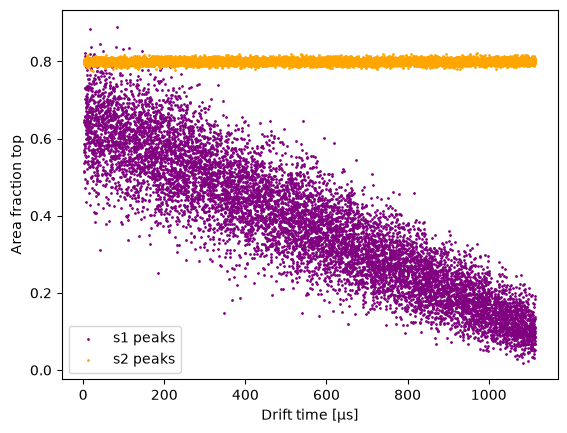

In [127]:
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s1_area_fraction_top'],
    s=1,
    color='purple',
    label='s1 peaks'
)
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s2_area_fraction_top'],
    s=1,
    color='orange',
    label='s2 peaks'
)
plt.xlabel('Drift time [µs]')
plt.ylabel('Area fraction top')
plt.legend()

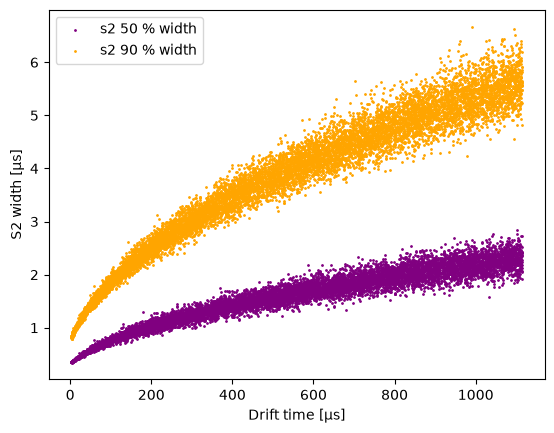

In [128]:
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s2_range_50p_area']/1000,
    s=1,
    color='purple',
    label='s2 50 % width'
)
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s2_range_90p_area']/1000,
    s=1,
    color='orange',
    label='s2 90 % width'
)
plt.xlabel('Drift time [µs]')
plt.ylabel('S2 width [µs]')
plt.legend()

Text(0, 0.5, 'S1 area [pe]')

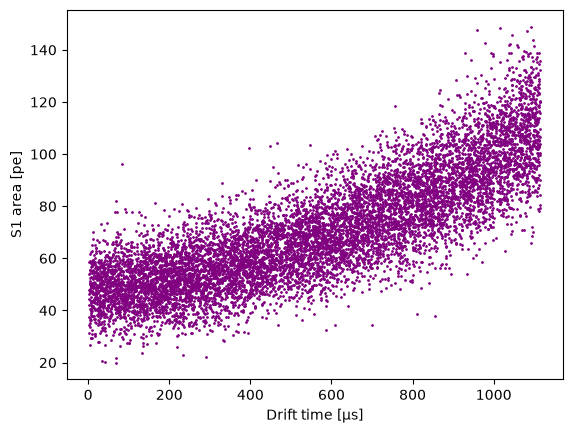

In [ ]:
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s1_area'],
    s=1,
    color='purple'
)
plt.xlabel('Drift time [µs]')
plt.ylabel('S1 area [pe]')

The maximum S1 area decreases for shorter drift times, i.e. for interactions closer to the top of the TPC. This is a position dependent change of the detector response which we need to correct for.

## Position reconstruction:

One strong suit of a liquid noble gas TPC is the possibility to reconstruct the position of the interaction vertex. As depicted in the subsequent figure the depth of an interaction which we commonly refer to as **z** can be reconstructed from the drift time and the drift velocity of the electron cloud. The lateral position parallel to the PMT arrays which we call **x** and **y** is reconstructed using the PMT hit pattern in the top PMT array.

<center><img src="images/tpc_nt.png" width="800"/></center>

By default abstrax does not offer yet any position reconstruction and all events are reconstructed at the position (0,0). In Tutorial 3 we will see how we can replace the current position reconstruction plugin with a simple weighted average. We will use this plugin already here as it is needed later. Feel free to ignore the subsequent code for the moment.

In [130]:
import numba

class SimplePositionReconstruction(strax.Plugin):
    """
    This plugin computes the position of an S2 peak as the
    weighted average over all PMT channels. The plugin uses 
    the convention that the first N PMTs are located in the 
    top PMT array.
    """
    __version__ = '0.0.1'
    
    depends_on = 'peaks'
    provides = 'peak_positions'

    n_top_pmts = strax.URLConfig(
        default="detector://n_top_pmts",
        type=int,
        track=True,
        help="Number of top-array PMT channels (channels 0 … n_top_pmts-1).",
    )

    pmt_channel_map = strax.URLConfig(
        default="pkg://pmt_positions_dummy.csv",
        track=True,
        help="Pandas DataFrame with PMT positions.",
    )

    parallel = True
    
    def infer_dtype(self):
        dtype = strax.time_fields + [
            (("Reconstructed X position of the peak, uncorrected [cm]", "x"), np.float32),
            (("Reconstructed Y position of the peak, uncorrected [cm]", "y"), np.float32),
        ]
        return dtype
    
    def compute(self, peaks):    
        
        result = np.zeros(
            len(peaks),
            self.dtype
        ) 
        result['time'] = peaks['time']
        result['endtime'] = strax.endtime(peaks)

        pmt_x_position = self.pmt_channel_map['x'].values[:self.n_top_pmts]
        pmt_y_position = self.pmt_channel_map['y'].values[:self.n_top_pmts]

        get_area_weighted_average(
            peaks, 
            result,
            pmt_x_position,
            pmt_y_position,
        )
        
        return result

@numba.njit
def get_area_weighted_average(
        peaks, 
        peak_positions,
        x_positions, 
        y_positions
        ):
    """Computes area weighted position of an S2 peak. Modifies
    peak positions array in place. 
    """ 
    n_top_pmts = len(x_positions)
    for index, peak in enumerate(peaks):
        
        _is_not_an_s2_peak = (peak['type'] != 2)
        if _is_not_an_s2_peak:
            continue

        area_per_channel = peak['area_per_channel'][:n_top_pmts]

        total_area = np.sum(area_per_channel)
        _is_not_seen_by_top_array = (total_area == 0)
        if _is_not_seen_by_top_array:
            continue

        x_mean = np.sum(x_positions*area_per_channel)/total_area
        y_mean = np.sum(y_positions*area_per_channel)/total_area
        peak_positions['x'][index] = x_mean
        peak_positions['y'][index] = y_mean


st.register(SimplePositionReconstruction)
event_basics = st.get_array(LONG_EMBER_RUN, 'event_basics')

Loading event_basics: |          | 0.00 % [00:00<?]

In case of a true experiment such a simplified position reconstruction is not sufficient as it comes with some artifacts and a mismatch between reconstructed and true positions.

In [131]:
tpc_radius = strax.URLConfig.evaluate_dry('detector://tpc_radius')

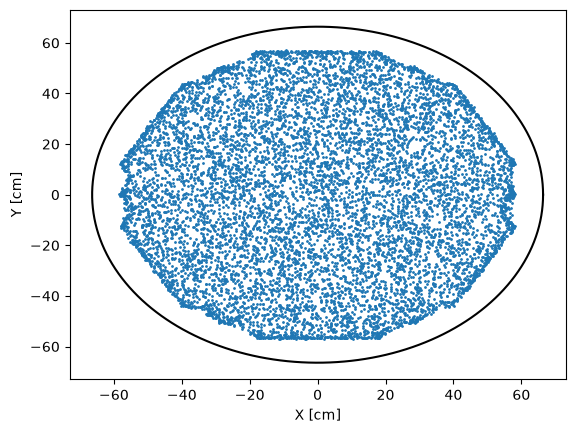

In [132]:
plt.scatter(
    event_basics['x'],
    event_basics['y'],
    s=1
)
plt.xlabel('X [cm]')
plt.ylabel('Y [cm]')
angle = np.linspace(0, 2*np.pi, 200)
plt.plot(
    tpc_radius*np.cos(angle),
    tpc_radius*np.sin(angle),
    color='k'
)

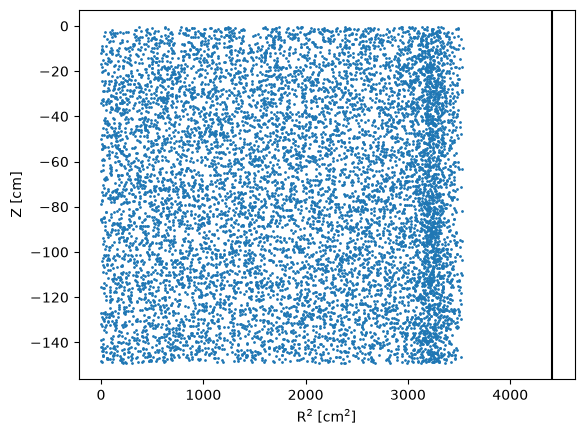

In [133]:
plt.scatter(
    event_basics['x']**2 + event_basics['y']**2,
    event_basics['z'],
    s=1
)
plt.xlabel('R$^2$ [cm$^2$]')
plt.ylabel('Z [cm]')
plt.axvline(tpc_radius**2, color='k')

We can see that this simplified method leads to a not complete representation of the detector and an artifact near the detector wall. However, a good position reconstruction is very application dependent and must be provided by yourself for your project.

## Signal corrections:

The signal reconstruction in a TPC is not perfect, since different spatial and temporal effects smear the reconstructed energy of an interaction.

The `CorrectedAreas` plugin corrects the main and alternative S1 and S2 for different effects. The dummy simulations we are using only apply two effects: a position dependent S1 light collection efficiency map and the z dependent loss of electrons due to the finite electron lifetime.

The basics idea behind corrections is, that the same monoenergetic event in the TPC should produce the same S1/S2 signal, no matter where or when it is recorded. However, we have time and space dependent effects in the detector. An easy one to imagine is the Light Collection Efficiency (LCE). At some positions of the detector, photons simply have a lower chance to reach our PMTs than at other positions. To ensure that each signal has the same S1/S2 area, we need to correct for this LCE for example.

In the following sections we want to provide a quick overview on the corrections in our signal reconstruction chain.

### Electron life time:

The maybe easiest to understand detector effect which biases our reconstructed signals is the so-called "electron lifetime". The electron *drift* lifetime represents the average lifetime of a free electron inside liquid xenon. The lifetime of the free electrons is mostly determined by the fraction of electro-negative impurities in the liquid like oxygen.

To study this effect mono-energetic signals can be used like our dummy 10 keV line:

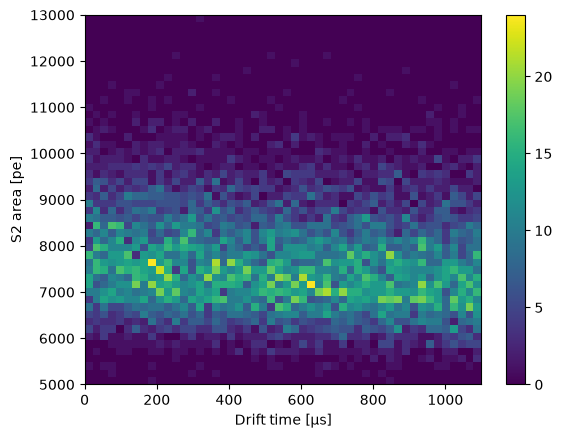

In [134]:
plt.hist2d(event_basics['drift_time']/10**3, event_basics['s2_area'], bins=(50, 50), range=((0, 1100), (5000, 13000)))
plt.colorbar()
plt.xlabel('Drift time [µs]')
plt.ylabel('S2 area [pe]')
plt.show()

The electron lifetime $\tau$ can be extracted from an exponential fit $S2(t) = S2(0) \cdot e^{-t/\tau}$ to the data, where $t$ is the drift time. A simple way to do this is to compute the median S2 area in slices of drift time and to fit a straight line to its logarithm:

Fitted electron lifetime: 19.0 ms


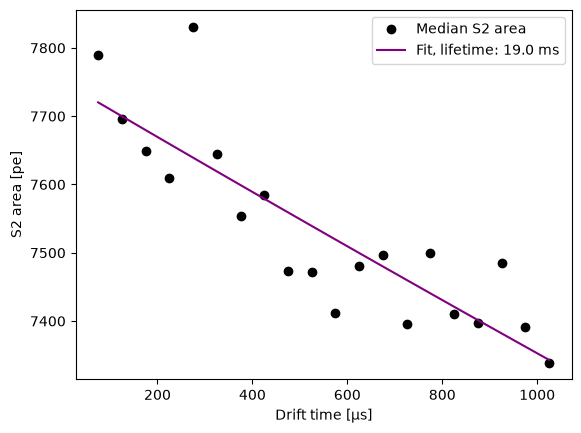

In [135]:
drift_time_bin_edges = np.arange(50_000, 1_100_000, 50_000)  # in ns
drift_time_bin_centers = []
median_s2_areas = []

for lower_edge, upper_edge in zip(drift_time_bin_edges[:-1], drift_time_bin_edges[1:]):
    _is_in_slice = (event_basics['drift_time'] >= lower_edge) & (event_basics['drift_time'] < upper_edge)
    drift_time_bin_centers.append((lower_edge + upper_edge) / 2)
    median_s2_areas.append(np.median(event_basics['s2_area'][_is_in_slice]))

drift_time_bin_centers = np.array(drift_time_bin_centers)
slope, offset = np.polyfit(drift_time_bin_centers, np.log(median_s2_areas), 1)
electron_lifetime = -1 / slope
print(f'Fitted electron lifetime: {electron_lifetime / 1e6:.1f} ms')

plt.plot(drift_time_bin_centers / 1000, median_s2_areas, 'o', color='k', label='Median S2 area')
plt.plot(drift_time_bin_centers / 1000, np.exp(offset + slope * drift_time_bin_centers),
         color='purple', label=f'Fit, lifetime: {electron_lifetime / 1e6:.1f} ms')
plt.xlabel('Drift time [µs]')
plt.ylabel('S2 area [pe]')
plt.legend()
plt.show()

The fitted value is close to the electron lifetime of 20 ms used in the simulation (`detector://electron_lifetime_liquid`). Since the lifetime is long compared to the maximum drift time of about 1.1 ms, only about 5 % of the electrons are lost even for interactions close to the cathode.

## S2 correction map:

Beside the electron lifetime the S2 area has also a lateral position dependence which is a convolution of three different effects. Due to the electric attraction between gate and anode, caused by the high electric field, the electric field varies in x and y. This leads to a position dependent electron extraction efficiency. Secondly, the gas gain of a single electron varies with field. The gas gain can be determined from single electron S2. Usually, one does not determine the number of photons emitted by the single electron, but the number of observed photoelectrons. Thus, the gas gain is typically convoluted with the light collection efficiency of the PMT arrays for the given position. Both of these effects lead to the average electron gain $g2$.

However, instead of correcting for these effects independently it is easier to apply just a single correction map which is a convolution of these different effects. In addition to this correction map time variations in the SE gain and extraction efficiency are absorbed in a time dependent scalar which scales the average of the correction map.

In our toy simulations no spatial dependent effects were simulated such that we can skip this correction here. To confirm this we can compare the average S2 area in an x/y bin compared to the overall detector average:

In [136]:
bin_edges = np.arange(-70, 71, 10)

number_of_events, _, _ = np.histogram2d(
    event_basics['x'], event_basics['y'], bins=(bin_edges, bin_edges)
)
summed_s2_area, _, _ = np.histogram2d(
    event_basics['x'], event_basics['y'], bins=(bin_edges, bin_edges), weights=event_basics['s2_area']
)

# Bins without any event are set to NaN to avoid a division by zero:
number_of_events[number_of_events == 0] = np.nan
relative_s2_area = summed_s2_area / number_of_events / np.mean(event_basics['s2_area'])

The variations are less than 5 %

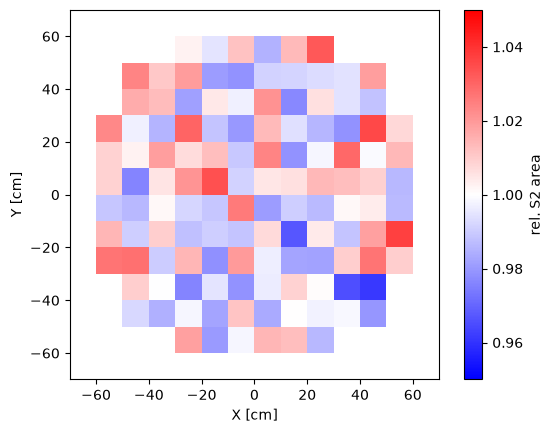

In [137]:
# np.histogram2d returns the array as [x, y], but pcolormesh expects [y, x], hence the .T
plt.pcolormesh(bin_edges, bin_edges, relative_s2_area.T, cmap='bwr', vmin=0.95, vmax=1.05)
plt.gca().set_aspect('equal')
plt.xlabel('X [cm]')
plt.ylabel('Y [cm]')
plt.colorbar(label='rel. S2 area')
plt.show()

### S1 correction map:

Similarly to the S2(x,y) map, S1 signals are corrected according to a map spanning over all three dimensions x, y, and z. The correction maps can also be determined based on a mono-energetic calibration line. A typical S1 light collection efficiency map is shown in the subsequent figure:

<center><img src="images/S1LCE.png" width="600"/></center>


We have already seen the impact of the light collection efficiency on our simulated data before: the S1 area depends on the depth of the interaction.

Text(0, 0.5, 'S1 area [pe]')

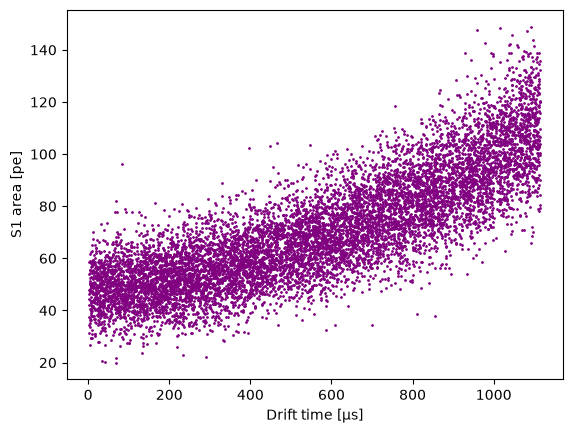

In [138]:
plt.scatter(
    event_basics['drift_time']/1000,
    event_basics['s1_area'],
    s=1,
    color='purple'
)
plt.xlabel('Drift time [µs]')
plt.ylabel('S1 area [pe]')

Since the production of such a map requires quite large statistics which are not available here, we simply use the relative S1 light yield map which was used in our ember simulation (`s1_lce_correction_map.pkl`, shipped with abstrax). `CorrectedAreas` divides the S1 area by the value of this map at the reconstructed position of the interaction. The correction might not be perfect, given the biased position reconstruction.

The electron lifetime correction is already applied by default with the value from `detector.yaml`. We set it here explicitly to the 20 ms (in ns) of the simulation to show where it is configured. Now we can change our settings to apply our corrections and compare the results before and after:

In [139]:
st.set_config(
    {'s1_xyz_map': 'grid_map://s1_lce_correction_map.pkl?method=linear',
     'electron_lifetime_liquid': 20000000
     }

)

Let's load `event_info` which contains `event_basics`, `corrected_areas` and `energy_estimates`.

In [140]:
event_info = st.get_array(LONG_EMBER_RUN, 'event_info')

Loading event_info: |          | 0.00 % [00:00<?]

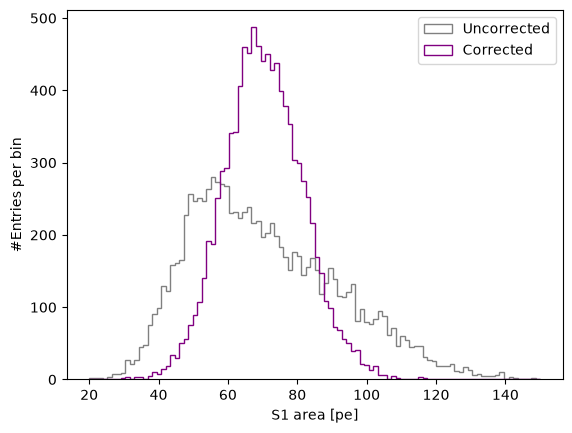

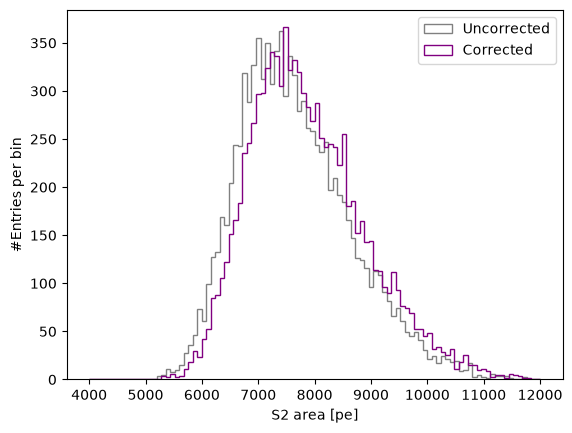

In [141]:
plt.hist(
    event_info['s1_area'],
    bins=100,
    range=(20, 150),
    histtype='step',
    color='gray',
    label='Uncorrected'
)
plt.hist(
    event_info['cs1'],
    bins=100,
    range=(20, 150),
    histtype='step',
    color='purple',
    label='Corrected'
)
plt.xlabel('S1 area [pe]')
plt.ylabel('#Entries per bin')
plt.legend()
plt.show()


plt.hist(
    event_info['s2_area'],
    bins=100,
    range=(4000, 12000),
    histtype='step',
    color='gray',
    label='Uncorrected'
)
plt.hist(
    event_info['cs2'],
    bins=100,
    range=(4000, 12000),
    histtype='step',
    color='purple',
    label='Corrected'
)
plt.xlabel('S2 area [pe]')
plt.ylabel('#Entries per bin')
plt.legend()
plt.show()

In [142]:
p = st.get_single_plugin(LONG_EMBER_RUN, 'energy_estimates')

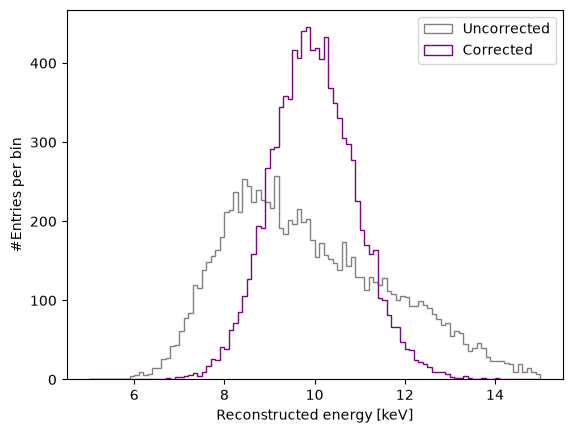

In [143]:
plt.hist(
    p.w_value_ev*(event_info['s1_area']/p.g1 + event_info['s2_area']/p.g2)/1000,
    bins=100,
    range=(5, 15),
    histtype='step',
    color='gray',
    label='Uncorrected'
)
plt.hist(
    event_info['e_ces'],
    bins=100,
    range=(5, 15),
    histtype='step',
    color='purple',
    label='Corrected'
)
plt.xlabel('Reconstructed energy [keV]')
plt.ylabel('#Entries per bin')
plt.legend()
plt.show()